# C1_03_Architecture_Ablation
- X = X_flat_c1_v2.npy
- Y = y_labels_c1_v2.csv
- Built by Garmin_C1_DataBuild

### Architecture sweep: width, depth, and GRU against LSTM

Models (seed 42): GRU 32x2 (reference), GRU 64x2, GRU 32x3, GRU 64x3, GRU 128x3, LSTM 32x2, LSTM 64x3.
- Width: 32x2 against 64x2.
- Depth: 32x2 against 32x3.
- Cell type: GRU against LSTM at the same size.

Training: Adam (learning rate 0.001), batch size 64, dropout and recurrent dropout 0.3, up to 60 epochs, early stopping (patience 8). Class weighting is not used.

Each finished run is saved to the results folder, and re-running skips the ones already done. 

## 1. Setup and configuration

In [3]:
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras

DATA_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed")
X_FLAT_PATH = DATA_DIR / "X_flat_c1_v2.npy"
Y_LABELS_PATH = DATA_DIR / "y_labels_c1_v2.csv"

RESULTS_DIR = DATA_DIR / "c1_architecture_ablation_2026-10-04"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = RESULTS_DIR / "results.csv"
FRESH_START = False          # True = ignore any saved results and re-run everything

# --- Training settings ---
MAX_EPOCHS = 60
PATIENCE = 8
BATCH_SIZE = 64
VERBOSE = 2
SWEEP_SEED = 42

DEFAULT_CFG = dict(arch="gru", units=32, layers=2, dropout=0.3, lr=1e-3, optimizer="adam")

CONFIGS = {
    "GRU 32x2 (reference)": dict(arch="gru", units=32, layers=2),
    "GRU 64x2":             dict(arch="gru", units=64, layers=2),
    "GRU 32x3":             dict(arch="gru", units=32, layers=3),
    "GRU 64x3 (V3)":        dict(arch="gru", units=64, layers=3),
    "GRU 128x3":            dict(arch="gru", units=128, layers=3),
    "LSTM 32x2":            dict(arch="lstm", units=32, layers=2),
    "LSTM 64x3":            dict(arch="lstm", units=64, layers=3),
}
CONFIGS_TO_RUN = list(CONFIGS)   # edit to run a subset (e.g. drop "GRU 128x3" to save time)
REFERENCE_NAME = "GRU 32x2 (reference)"

# Reference numbers from C1_01_Baselines (same VAL windows).
REFERENCE_RESULTS = {"Naive": 0.397, "Random Forest": 0.567, "Simple DNN": 0.575}


## 2. Load data, split by run, scale

The split is the same as in the baselines (random_state=42 at both levels), so the TRAIN and VAL windows are identical. The test runs are set aside and never built.


In [4]:
X_flat = np.load(X_FLAT_PATH)
y_labels_df = pd.read_csv(Y_LABELS_PATH, parse_dates=["date"])
assert len(X_flat) == len(y_labels_df), "X and Y row counts differ"
print(f"Loaded X_flat {X_flat.shape}, {len(y_labels_df)} labelled windows")

# Column layout in X_flat: [0:30]=HR, [30:60]=speed, [60:90]=cadence, [90:120]=temperature, [120]=distance
X_sequence = np.stack(
    [X_flat[:, 0:30], X_flat[:, 30:60], X_flat[:, 60:90], X_flat[:, 90:120]], axis=-1
).astype("float32")                                   # (n_windows, 30, 4)

le = LabelEncoder()
y_all = le.fit_transform(y_labels_df["c1_target"])
n_classes = len(le.classes_)
print("Classes:", dict(zip(le.classes_, range(n_classes))))

run_idx_all = y_labels_df["run_idx"].to_numpy()
unique_runs = np.unique(run_idx_all)

# The test runs are set aside here and never built.
train_runs, held_out_runs = train_test_split(unique_runs, test_size=0.2, random_state=42)
trainval_idx = np.where(np.isin(run_idx_all, train_runs))[0]

trainval_run_idx = run_idx_all[trainval_idx]
fit_runs, val_runs = train_test_split(np.unique(trainval_run_idx), test_size=0.15, random_state=42)
fit_idx = trainval_idx[np.isin(trainval_run_idx, fit_runs)]
val_idx = trainval_idx[np.isin(trainval_run_idx, val_runs)]

X_fit_raw, X_val_raw = X_sequence[fit_idx], X_sequence[val_idx]
y_fit, y_val = y_all[fit_idx], y_all[val_idx]

n_fit, timesteps, n_channels = X_fit_raw.shape
scaler = StandardScaler()                              # fit on FIT windows only
X_fit = scaler.fit_transform(X_fit_raw.reshape(-1, n_channels)).reshape(n_fit, timesteps, n_channels).astype("float32")
X_val = scaler.transform(X_val_raw.reshape(-1, n_channels)).reshape(len(X_val_raw), timesteps, n_channels).astype("float32")

print(f"\nFit:  {len(y_fit)} windows from {len(fit_runs)} runs")
print(f"Val:  {len(y_val)} windows from {len(val_runs)} runs")
print("(test runs excluded and never built)")
print("\nValidation class counts:", dict(zip(le.classes_, np.bincount(y_val, minlength=n_classes))))
print(f"Majority-class (naive) validation accuracy: {np.bincount(y_val).max() / len(y_val):.3f}")

# Fixed subsample of FIT windows, used to measure train accuracy in inference mode
# (Keras's logged train accuracy has dropout switched on, which understates it).
_rng = np.random.default_rng(0)
_sub = _rng.choice(len(X_fit), size=min(20000, len(X_fit)), replace=False)
X_fit_sub, y_fit_sub = X_fit[_sub], y_fit[_sub]


Loaded X_flat (197341, 121), 197341 labelled windows
Classes: {'Base': 0, 'Declining': 1, 'Improving': 2, 'Recovery': 3}

Fit:  132966 windows from 1275 runs
Val:  24545 windows from 225 runs
(test runs excluded and never built)

Validation class counts: {'Base': np.int64(9739), 'Declining': np.int64(7733), 'Improving': np.int64(6585), 'Recovery': np.int64(488)}
Majority-class (naive) validation accuracy: 0.397


## 3. Helpers: model builder, resumable experiment runner

In [5]:
def safe(text):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", text)


def make_id(stage, name, seed):
    return f"{stage}|{name}|seed{seed}"


def build_model(arch, units, layers, dropout, lr, optimizer):
    """Recurrent dropout and the Dropout layer share one rate."""
    Layer = keras.layers.GRU if arch == "gru" else keras.layers.LSTM
    inputs = keras.layers.Input(shape=(timesteps, n_channels))
    x = inputs
    for i in range(layers):
        is_last = (i == layers - 1)
        x = Layer(units, recurrent_dropout=dropout, return_sequences=not is_last)(x)
    x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs)

    if optimizer == "adam":
        opt = keras.optimizers.Adam(learning_rate=lr)
    elif optimizer == "rmsprop":
        opt = keras.optimizers.RMSprop(learning_rate=lr)
    else:
        raise ValueError(f"unknown optimizer {optimizer}")
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


if RESULTS_CSV.exists() and not FRESH_START:
    results_df = pd.read_csv(RESULTS_CSV)
    print(f"Loaded {len(results_df)} saved results from {RESULTS_CSV}")
else:
    results_df = pd.DataFrame()


def run_experiment(stage, name, cfg, seed):
    """Train one config/seed, log metrics, save predictions + history. Skips finished runs."""
    global results_df
    run_id = make_id(stage, name, seed)
    if not results_df.empty and run_id in set(results_df["run_id"]):
        print(f"[skip] {run_id} (already in results log)")
        return results_df[results_df["run_id"] == run_id].iloc[0].to_dict()

    full_cfg = {**DEFAULT_CFG, **cfg}
    print(f"\n=== {run_id} | {full_cfg} ===")
    keras.utils.set_random_seed(seed)
    model = build_model(**full_cfg)

    t0 = time.time()
    history = model.fit(
        X_fit, y_fit,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, verbose=VERBOSE,
        callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)],
    )
    minutes = (time.time() - t0) / 60

    pred = model.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)   # best-epoch weights restored
    val_acc = accuracy_score(y_val, pred)
    macro_f1 = f1_score(y_val, pred, average="macro")
    recalls = recall_score(y_val, pred, average=None, labels=np.arange(n_classes), zero_division=0)
    _, fit_acc_eval = model.evaluate(X_fit_sub, y_fit_sub, batch_size=1024, verbose=0)
    val_losses = history.history["val_loss"]
    best_epoch = int(np.argmin(val_losses))

    row = {
        "run_id": run_id, "stage": stage, "name": name, "seed": seed,
        "arch": full_cfg["arch"], "units": full_cfg["units"], "layers": full_cfg["layers"],
        "dropout": full_cfg["dropout"], "lr": full_cfg["lr"], "optimizer": full_cfg["optimizer"],
        "params": int(model.count_params()),
        "best_epoch": best_epoch + 1, "epochs_run": len(val_losses),
        "val_acc": float(val_acc), "macro_f1": float(macro_f1),
        "val_loss": float(min(val_losses)),
        "fit_acc_eval": float(fit_acc_eval), "gap_acc": float(fit_acc_eval - val_acc),
        "minutes": float(minutes),
    }
    for cls, r in zip(le.classes_, recalls):
        row[f"recall_{cls}"] = float(r)

    np.save(RESULTS_DIR / f"pred_{safe(run_id)}.npy", pred)
    with open(RESULTS_DIR / f"hist_{safe(run_id)}.json", "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f)

    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
    results_df.to_csv(RESULTS_CSV, index=False)
    print(f"-> val_acc {val_acc:.3f} | macro-F1 {macro_f1:.3f} | train(eval) {fit_acc_eval:.3f} | "
          f"gap {fit_acc_eval - val_acc:+.3f} | best epoch {best_epoch + 1} | {minutes:.1f} min")
    keras.backend.clear_session()
    return row


RECALL_COLS = [f"recall_{c}" for c in le.classes_]


Loaded 9 saved results from C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed\c1_architecture_ablation_2026-10-04\results.csv


## 4. Sweep: width, depth, and GRU against LSTM (seed 42)

The seven models are compared in pairs, so each comparison changes one thing:
- **Width:** GRU 32x2 against GRU 64x2.
- **Depth:** GRU 32x2 against GRU 32x3.
- **Cell type:** GRU against LSTM at the same size (32x2 and 64x3).


In [4]:
for name in CONFIGS_TO_RUN:
    run_experiment("sweep", name, CONFIGS[name], SWEEP_SEED)

sweep_df = results_df[results_df["stage"] == "sweep"].copy()
show_cols = ["name", "params", "best_epoch", "val_acc", "macro_f1"] + RECALL_COLS + ["val_loss", "fit_acc_eval", "gap_acc", "minutes"]
print("\nSweep results (seed 42), best first:")
print(sweep_df.sort_values("val_acc", ascending=False)[show_cols].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("\nReference points (same split): " + ", ".join(f"{k} {v:.3f}" for k, v in REFERENCE_RESULTS.items()))



=== sweep|GRU 32x2 (reference)|seed42 | {'arch': 'gru', 'units': 32, 'layers': 2, 'dropout': 0.3, 'lr': 0.001, 'optimizer': 'adam'} ===
Epoch 1/60
2078/2078 - 95s - 46ms/step - accuracy: 0.5016 - loss: 1.0153 - val_accuracy: 0.5559 - val_loss: 0.9500
Epoch 2/60
2078/2078 - 95s - 46ms/step - accuracy: 0.5448 - loss: 0.9642 - val_accuracy: 0.5639 - val_loss: 0.9356
Epoch 3/60
2078/2078 - 139s - 67ms/step - accuracy: 0.5550 - loss: 0.9527 - val_accuracy: 0.5684 - val_loss: 0.9280
Epoch 4/60
2078/2078 - 136s - 65ms/step - accuracy: 0.5593 - loss: 0.9458 - val_accuracy: 0.5696 - val_loss: 0.9229
Epoch 5/60
2078/2078 - 146s - 70ms/step - accuracy: 0.5636 - loss: 0.9409 - val_accuracy: 0.5737 - val_loss: 0.9204
Epoch 6/60
2078/2078 - 144s - 69ms/step - accuracy: 0.5665 - loss: 0.9370 - val_accuracy: 0.5758 - val_loss: 0.9173
Epoch 7/60
2078/2078 - 93s - 45ms/step - accuracy: 0.5678 - loss: 0.9340 - val_accuracy: 0.5771 - val_loss: 0.9146
Epoch 8/60
2078/2078 - 138s - 66ms/step - accuracy: 0.

### 4b. Loss curves and train-validation gap

Validation loss by epoch for each model, and the gap between train and validation accuracy. Train accuracy is measured with dropout off, on a fixed sample of 20,000 TRAIN windows. A larger gap means more overfitting.


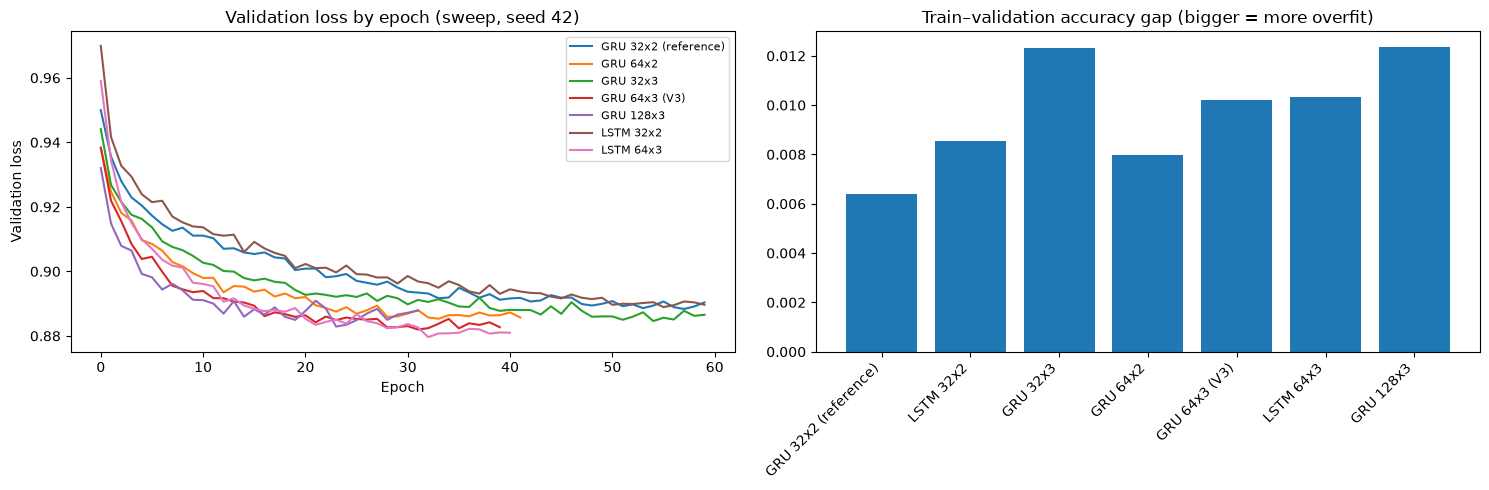

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for _, r in sweep_df.iterrows():
    with open(RESULTS_DIR / f"hist_{safe(r['run_id'])}.json") as f:
        hist = json.load(f)
    axes[0].plot(hist["val_loss"], label=r["name"])
axes[0].set_title("Validation loss by epoch (sweep, seed 42)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation loss")
axes[0].legend(fontsize=8)

order = sweep_df.sort_values("params")
axes[1].bar(order["name"], order["gap_acc"])
axes[1].set_title("Train\u2013validation accuracy gap (bigger = more overfit)")
axes[1].tick_params(axis="x", rotation=45)
for lbl in axes[1].get_xticklabels():
    lbl.set_ha("right")
plt.tight_layout()
plt.show()


## 5. Diagnostics for the winner

Classification report and confusion matrix for the best model in the sweep, on the VAL windows.

                name  params  val_acc  macro_f1
GRU 32x2 (reference)   10116 0.588715  0.633464
            GRU 64x2   38660 0.588307  0.636550
            GRU 32x3   16452 0.586840  0.631537
       GRU 64x3 (V3)   63620 0.593726  0.640147
           GRU 128x3  250116 0.590426  0.630957
           LSTM 32x2   13188 0.587452  0.629452
           LSTM 64x3   83972 0.591770  0.641305
Winner: GRU 64x3 (V3) (seed 42), validation accuracy 0.594

              precision    recall  f1-score   support

        Base       0.56      0.67      0.61      9739
   Declining       0.61      0.57      0.59      7733
   Improving       0.63      0.50      0.56      6585
    Recovery       0.80      0.81      0.81       488

    accuracy                           0.59     24545
   macro avg       0.65      0.64      0.64     24545
weighted avg       0.60      0.59      0.59     24545



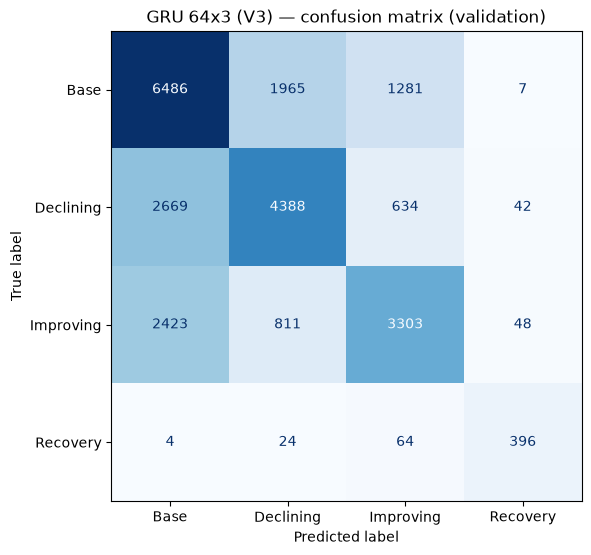


=== SUMMARY (validation accuracy, run-level split) ===
Naive                                         0.397
Random Forest                                 0.567
Simple DNN                                    0.575
GRU 32x2 (reference)                          0.589
GRU 64x3 (V3)                                 0.594


In [7]:
sweep_df = results_df[results_df["stage"] == "sweep"].copy()
print(sweep_df[["name", "params", "val_acc", "macro_f1"]].to_string(index=False))

winner_name = sweep_df.sort_values("val_acc", ascending=False).iloc[0]["name"]
winner_id = make_id("sweep", winner_name, SWEEP_SEED)
pred = np.load(RESULTS_DIR / f"pred_{safe(winner_id)}.npy")

print(f"Winner: {winner_name} (seed {SWEEP_SEED}), validation accuracy {accuracy_score(y_val, pred):.3f}\n")
print(classification_report(y_val, pred, labels=np.arange(n_classes), target_names=le.classes_, zero_division=0))

cm = confusion_matrix(y_val, pred, labels=np.arange(n_classes))
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{winner_name} \u2014 confusion matrix (validation)")
plt.tight_layout()
plt.show()

print("\n=== SUMMARY (validation accuracy, run-level split) ===")
for k, v in REFERENCE_RESULTS.items():
    print(f"{k:<46}{v:.3f}")
sweep_acc = sweep_df.set_index("name")["val_acc"]
print(f"{REFERENCE_NAME:<46}{sweep_acc[REFERENCE_NAME]:.3f}")
print(f"{winner_name:<46}{sweep_acc[winner_name]:.3f}")